# Commodity Price Forecasting — Modelling
### Project by Rayan Rawat

This notebook builds and compares 4 forecasting models for BRENT crude oil:
- Model 1: SARIMA (Statistical baseline)
- Model 2: Prophet (Seasonality-aware)
- Model 3: XGBoost (Machine Learning)
- Model 4: LSTM (Deep Learning)

**Target:** BRENT Crude Oil closing price
**Train:** 2010–2022 | **Test:** 2023–2026
**Evaluation metrics:** MAE, RMSE, MAPE

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
import os

# Statistical model
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8')

print("All libraries imported successfully!")

All libraries imported successfully!


We load only BRENT data for modelling.
All other commodities are set aside — we focus on one commodity
to build deep, accurate models rather than shallow models for all five.

In [2]:
df = pd.read_csv('data/BRENT.csv', 
                  index_col='Date', 
                  parse_dates=True)

# Rename columns properly
column_mapping = {
    'C': 'Close', 'H': 'High',
    'L': 'Low', 'O': 'Open', 'V': 'Volume'
}
df.rename(columns=column_mapping, inplace=True)

# Keep only closing price for now
brent = df[['Close']].copy()

# Add log returns column
brent['Log_Return'] = np.log(brent['Close'] / brent['Close'].shift(1))

# Basic check
print(f"Shape        : {brent.shape}")
print(f"Date range   : {brent.index[0].date()} to {brent.index[-1].date()}")
print(f"Missing values: {brent.isnull().sum().sum()}")
print(f"\nFirst 5 rows:")
print(brent.head())

Shape        : (4187, 2)
Date range   : 2010-01-04 to 2026-10-09
Missing values: 1

First 5 rows:
                Close  Log_Return
Date                             
2010-01-04  80.120003         NaN
2010-01-05  80.589996    0.005849
2010-01-06  81.889999    0.016002
2010-01-07  81.510002   -0.004651
2010-01-08  81.370003   -0.001719


We split data into training (2010-2022) and testing (2023-2026).
Model learns from training data and is evaluated on unseen test data.
This gives us an honest measure of real world forecast accuracy.

Training set : 2010-01-04 to 2022-12-30 — 3238 days
Testing set  : 2023-01-03 to 2026-10-09 — 949 days
Train/Test   : 77.3% / 22.7%


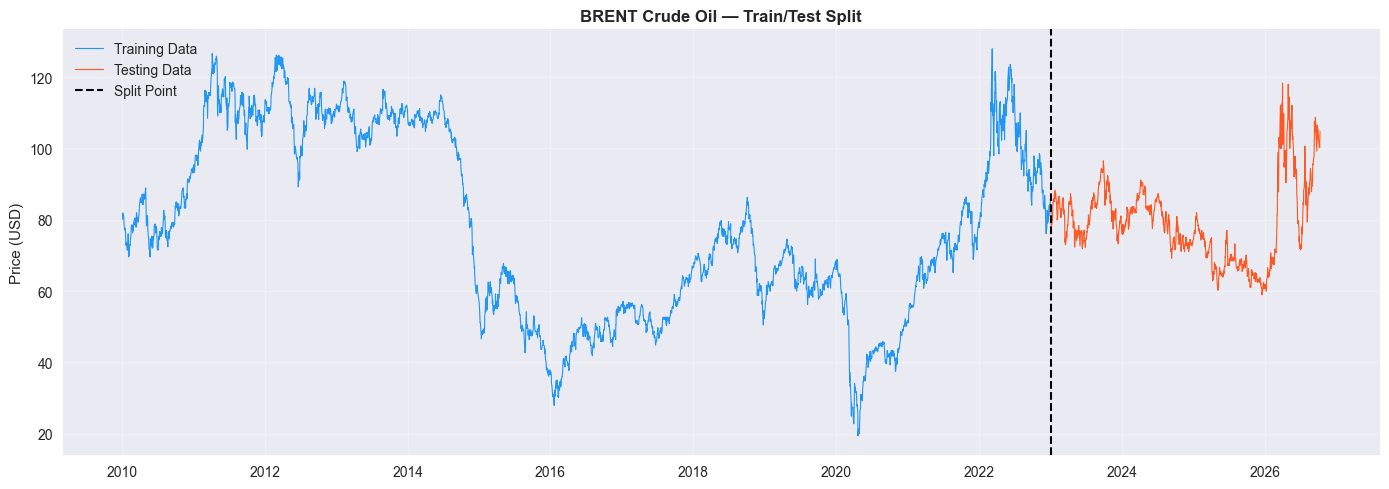

Chart saved!


In [3]:
split_date = '2023-01-01'

# Split into train and test
train = brent[brent.index < split_date]
test = brent[brent.index >= split_date]

print(f"Training set : {train.index[0].date()} to {train.index[-1].date()} — {len(train)} days")
print(f"Testing set  : {test.index[0].date()} to {test.index[-1].date()} — {len(test)} days")
print(f"Train/Test   : {len(train)/(len(train)+len(test))*100:.1f}% / {len(test)/(len(train)+len(test))*100:.1f}%")

# Visualise the split
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(train.index, train['Close'], 
        color='#2196F3', linewidth=0.8, label='Training Data')
ax.plot(test.index, test['Close'],
        color='#FF5722', linewidth=0.8, label='Testing Data')

ax.axvline(pd.Timestamp(split_date), color='black',
           linestyle='--', linewidth=1.5, label='Split Point')

ax.set_title('BRENT Crude Oil — Train/Test Split', fontweight='bold')
ax.set_ylabel('Price (USD)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/train_test_split.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved!")

In [4]:
pip install pmdarima

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Model 1 — SARIMA
Statistical baseline model.
We use auto_arima to automatically find optimal parameters
based on AIC score, then forecast on test data.

In [5]:
from pmdarima import auto_arima

print("Finding optimal SARIMA parameters...")
print("This will take 2-3 minutes — auto_arima is trying many combinations\n")

# auto_arima automatically finds best p,d,q parameters
sarima_model = auto_arima(
    train['Close'],
    start_p=0, max_p=3,      # try p values 0,1,2,3
    start_q=0, max_q=3,      # try q values 0,1,2,3
    d=1,                      # we know d=1 from stationarity tests
    seasonal=False,           # no seasonal component for now (speeds up)
    information_criterion='aic',  # use AIC to pick best model
    stepwise=True,            # smart search, not brute force
    suppress_warnings=True,
    error_action='ignore'
)

print(f"Best parameters found: {sarima_model.order}")
print(f"\nModel Summary:")
print(sarima_model.summary())

Finding optimal SARIMA parameters...
This will take 2-3 minutes — auto_arima is trying many combinations

Best parameters found: (0, 1, 0)

Model Summary:
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 3238
Model:               SARIMAX(0, 1, 0)   Log Likelihood               -6094.450
Date:                Wed, 14 Oct 2026   AIC                          12190.901
Time:                        22:36:13   BIC                          12196.983
Sample:                             0   HQIC                         12193.080
                               - 3238                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         2.5285      0.027     93.610      0.000 

## SARIMA — Forecast and Evaluation
We generate forecasts for the test period (2023-2026)
and compare against actual prices using MAE, RMSE and MAPE.

Forecasting 949 days ahead...
Forecast NaN count: 0
First 5 forecasted values:
Date
2023-01-03    85.910004
2023-01-04    85.910004
2023-01-05    85.910004
2023-01-06    85.910004
2023-01-09    85.910004
Name: SARIMA_Forecast, dtype: float64

SARIMA MODEL PERFORMANCE
  MAE  : $10.75  (avg dollar error per day)
  RMSE : $13.03  (penalises large errors)
  MAPE : 14.49% (avg % error per day)


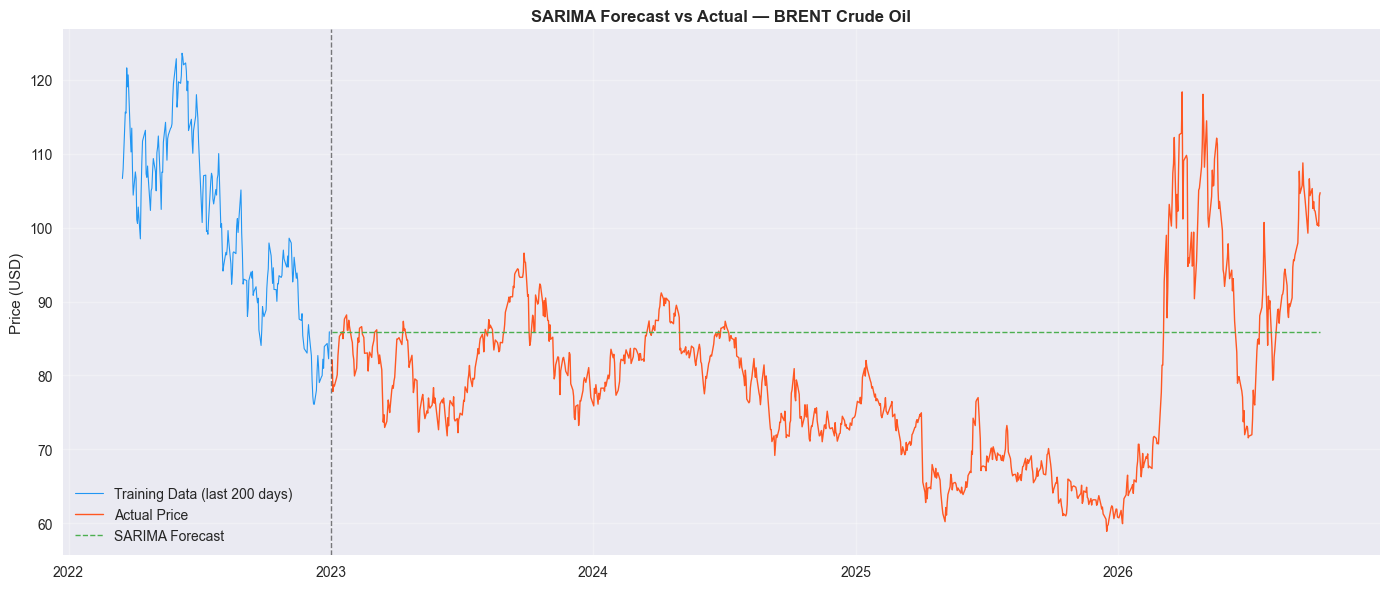


Chart saved!


In [6]:
n_forecast = len(test)

print(f"Forecasting {n_forecast} days ahead...")

# Generate forecast using predict with start and end dates
sarima_forecast_values = sarima_model.predict(n_periods=n_forecast)

# Convert numpy array directly to series with test index
sarima_forecast = pd.Series(
    sarima_forecast_values.tolist(),
    index=test.index,
    name='SARIMA_Forecast'
)

# Quick check
print(f"Forecast NaN count: {sarima_forecast.isnull().sum()}")
print(f"First 5 forecasted values:")
print(sarima_forecast.head())

# ── Evaluation Metrics ──────────────────────────────────────
actual = test['Close'].values
predicted = sarima_forecast.values

mae  = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = np.mean(np.abs((actual - predicted) / actual)) * 100

print("\n" + "="*50)
print("SARIMA MODEL PERFORMANCE")
print("="*50)
print(f"  MAE  : ${mae:.2f}  (avg dollar error per day)")
print(f"  RMSE : ${rmse:.2f}  (penalises large errors)")
print(f"  MAPE : {mape:.2f}% (avg % error per day)")

# ── Plot Actual vs Forecast ──────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(train.index[-200:], train['Close'][-200:],
        color='#2196F3', linewidth=0.8, label='Training Data (last 200 days)')
ax.plot(test.index, test['Close'],
        color='#FF5722', linewidth=1, label='Actual Price')
ax.plot(test.index, sarima_forecast,
        color='#4CAF50', linewidth=1,
        linestyle='--', label='SARIMA Forecast')

ax.axvline(pd.Timestamp('2023-01-01'), color='black',
           linestyle='--', linewidth=1, alpha=0.5)

ax.set_title('SARIMA Forecast vs Actual — BRENT Crude Oil',
             fontweight='bold')
ax.set_ylabel('Price (USD)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/sarima_forecast.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nChart saved!")

## Model Comparison Tracker
We track all model results here and update after each model.

In [7]:
# ============================================================
# MODEL COMPARISON TABLE — updated after each model
# ============================================================

results = {
    'Naive'  : {'MAE': None, 'RMSE': None, 'MAPE': 1.69},
    'SARIMA' : {'MAE': 10.75, 'RMSE': 13.03, 'MAPE': 14.49},
    'Prophet': {'MAE': 10.70, 'RMSE': 13.05, 'MAPE': 12.99},
    'XGBoost': {'MAE':  1.03, 'RMSE':  1.57, 'MAPE':  1.26},
    'LSTM'   : {'MAE':  1.88, 'RMSE':  2.64, 'MAPE':  2.29},
}

results_df = pd.DataFrame(results).T
results_df.index.name = 'Model'

print("="*50)
print("FINAL MODEL COMPARISON TABLE")
print("="*50)
print(results_df.to_string())
print("\nLower is better for all metrics")
print(f"\nBest model: XGBoost with MAPE of 1.26%")

FINAL MODEL COMPARISON TABLE
           MAE   RMSE   MAPE
Model                       
Naive      NaN    NaN   1.69
SARIMA   10.75  13.03  14.49
Prophet  10.70  13.05  12.99
XGBoost   1.03   1.57   1.26
LSTM      1.88   2.64   2.29

Lower is better for all metrics

Best model: XGBoost with MAPE of 1.26%


In [8]:
pip install prophet

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Model 2 — Prophet
Facebook's forecasting library that explicitly models:
- Trend with automatic changepoint detection
- Annual seasonality
- Special events/holidays

Advantage over SARIMA: handles non-stationary data directly
and captures seasonal patterns explicitly.

In [9]:
from prophet import Prophet

# Prophet requires specific column names: ds and y
# ds = datestamp, y = value to forecast
prophet_df = brent[['Close']].reset_index()
prophet_df.columns = ['ds', 'y']

print("Data formatted for Prophet:")
print(prophet_df.head())
print(f"\nShape: {prophet_df.shape}")

Data formatted for Prophet:
          ds          y
0 2010-01-04  80.120003
1 2010-01-05  80.589996
2 2010-01-06  81.889999
3 2010-01-07  81.510002
4 2010-01-08  81.370003

Shape: (4187, 2)


## Prophet — Train, Forecast and Evaluate
We split data into train/test, fit Prophet on training data,
forecast test period and compare against actual prices.

In [10]:
prophet_df_log = prophet_df.copy()
prophet_df_log['y'] = np.log(prophet_df_log['y'])

# Split into train and test
train_prophet = prophet_df_log[prophet_df_log['ds'] < '2023-01-01']
test_prophet  = prophet_df_log[prophet_df_log['ds'] >= '2023-01-01']

print(f"Train size: {len(train_prophet)} days")
print(f"Test size : {len(test_prophet)} days")

# Build Prophet model with more conservative trend
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.001,  # very conservative trend
    seasonality_prior_scale=0.1
)

print("\nFitting Prophet model...")
prophet_model.fit(train_prophet)
print("Model fitted successfully!")

Train size: 3238 days
Test size : 949 days

Fitting Prophet model...


22:36:17 - cmdstanpy - INFO - Chain [1] start processing
22:36:17 - cmdstanpy - INFO - Chain [1] done processing


Model fitted successfully!


## Prophet — Generate Forecast
We create a future dataframe for the test period
and generate predictions with confidence intervals.

PROPHET MODEL PERFORMANCE
  MAE  : $10.70
  RMSE : $13.05
  MAPE : 12.99%


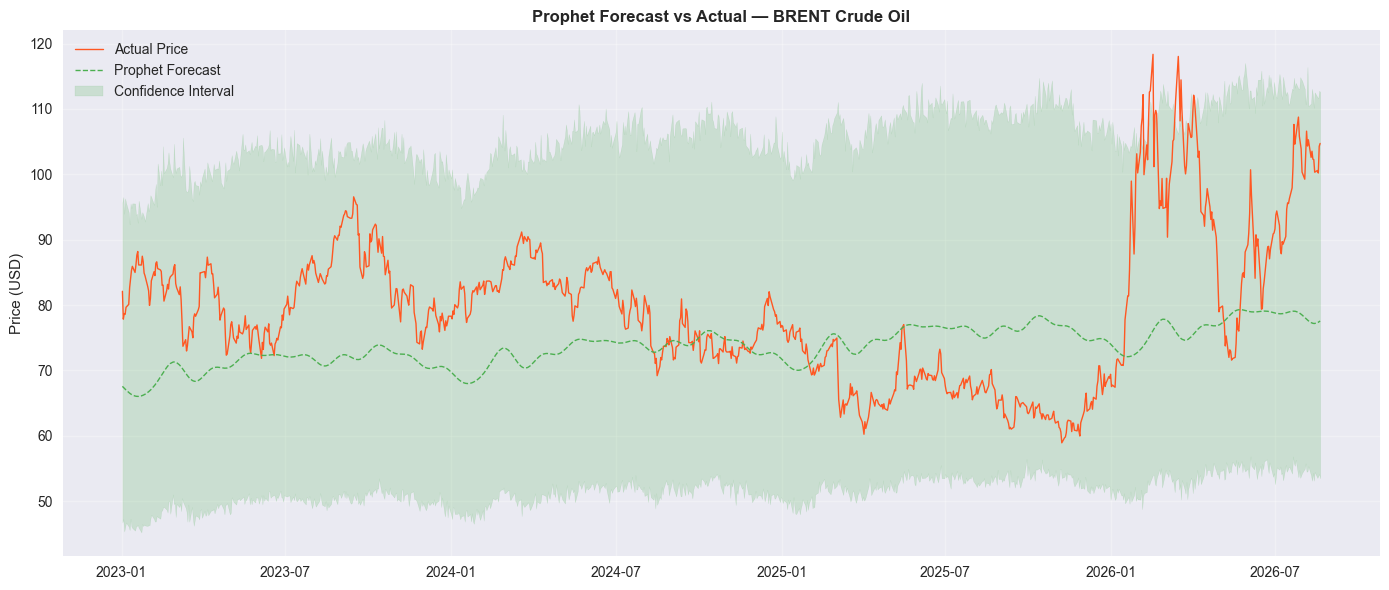


Chart saved!


In [11]:
future = prophet_model.make_future_dataframe(
    periods=len(test_prophet),
    freq='B'
)

# Generate forecast
forecast = prophet_model.predict(future)

# Extract test period
forecast_test = forecast[forecast['ds'] >= '2023-01-01'].copy()

# Convert predictions back from log to actual prices
min_len = min(len(test_prophet), len(forecast_test))

# actual prices (convert back from log)
actual_prophet    = np.exp(test_prophet['y'].values[:min_len])
predicted_prophet = np.exp(forecast_test['yhat'].values[:min_len])
lower_prophet     = np.exp(forecast_test['yhat_lower'].values[:min_len])
upper_prophet     = np.exp(forecast_test['yhat_upper'].values[:min_len])
dates_prophet     = forecast_test['ds'].values[:min_len]

# ── Evaluation Metrics ──────────────────────────────────────
mae_p  = mean_absolute_error(actual_prophet, predicted_prophet)
rmse_p = np.sqrt(mean_squared_error(actual_prophet, predicted_prophet))
mape_p = np.mean(np.abs((actual_prophet - predicted_prophet) /
                          actual_prophet)) * 100

print("="*45)
print("PROPHET MODEL PERFORMANCE")
print("="*45)
print(f"  MAE  : ${mae_p:.2f}")
print(f"  RMSE : ${rmse_p:.2f}")
print(f"  MAPE : {mape_p:.2f}%")

# ── Plot ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(dates_prophet, actual_prophet,
        color='#FF5722', linewidth=1, label='Actual Price')
ax.plot(dates_prophet, predicted_prophet,
        color='#4CAF50', linewidth=1,
        linestyle='--', label='Prophet Forecast')
ax.fill_between(dates_prophet, lower_prophet, upper_prophet,
                alpha=0.2, color='#4CAF50', label='Confidence Interval')

ax.set_title('Prophet Forecast vs Actual — BRENT Crude Oil',
             fontweight='bold')
ax.set_ylabel('Price (USD)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/prophet_forecast.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nChart saved!")

## Model 3 — XGBoost
Machine learning approach using engineered features.
Unlike SARIMA/Prophet which extrapolate trends,
XGBoost learns relationships between features and target price.

Features used:
- Lag prices (1, 5, 21, 63 days)
- Rolling statistics (mean, std)
- Calendar features (month, quarter, day of week)
- Return features (momentum signals)

In [12]:
def create_features(df):
    """
    Creates all features for XGBoost from raw price data.
    Input  : dataframe with Close and Log_Return columns
    Output : dataframe with 20+ engineered features
    """
    df = df.copy()
    
    # ── Lag Features ─────────────────────────────────────────
    # Past prices — most important features
    df['lag_1']  = df['Close'].shift(1)
    df['lag_5']  = df['Close'].shift(5)
    df['lag_21'] = df['Close'].shift(21)
    df['lag_63'] = df['Close'].shift(63)
    
    # ── Rolling Statistics ────────────────────────────────────
    # Recent trend and volatility
    df['rolling_mean_5']  = df['Close'].shift(1).rolling(5).mean()
    df['rolling_mean_21'] = df['Close'].shift(1).rolling(21).mean()
    df['rolling_mean_63'] = df['Close'].shift(1).rolling(63).mean()
    df['rolling_std_21']  = df['Close'].shift(1).rolling(21).std()
    df['rolling_std_63']  = df['Close'].shift(1).rolling(63).std()
    
    # ── Return Features ───────────────────────────────────────
    # Momentum signals
    df['return_1d']  = df['Log_Return'].shift(1)
    df['return_5d']  = df['Log_Return'].shift(1).rolling(5).sum()
    df['return_21d'] = df['Log_Return'].shift(1).rolling(21).sum()
    
    # ── Calendar Features ─────────────────────────────────────
    # Seasonal patterns
    df['month']       = df.index.month
    df['quarter']     = df.index.quarter
    df['day_of_week'] = df.index.dayofweek
    df['week_of_year']= df.index.isocalendar().week.astype(int)
    
    # ── Price Ratio Features ──────────────────────────────────
    # Where is price relative to recent average?
    df['price_to_ma21'] = df['Close'] / df['rolling_mean_21']
    df['price_to_ma63'] = df['Close'] / df['rolling_mean_63']
    
    # ── Volatility Ratio ──────────────────────────────────────
    # Is volatility expanding or contracting?
    df['vol_ratio'] = df['rolling_std_21'] / df['rolling_std_63']
    
    return df

# Apply feature engineering
brent_features = create_features(brent)

# Drop rows with NaN — created by lag and rolling calculations
brent_features = brent_features.dropna()

print(f"Shape after feature engineering: {brent_features.shape}")
print(f"\nFeatures created:")
for col in brent_features.columns:
    print(f"  {col}")

Shape after feature engineering: (4124, 21)

Features created:
  Close
  Log_Return
  lag_1
  lag_5
  lag_21
  lag_63
  rolling_mean_5
  rolling_mean_21
  rolling_mean_63
  rolling_std_21
  rolling_std_63
  return_1d
  return_5d
  return_21d
  month
  quarter
  day_of_week
  week_of_year
  price_to_ma21
  price_to_ma63
  vol_ratio


## XGBoost — Train and Forecast
We define features and target, split into train/test,
train XGBoost and evaluate performance.

In [13]:
from xgboost import XGBRegressor

# Define features and target
feature_cols = [
    'lag_1', 'lag_5', 'lag_21', 'lag_63',
    'rolling_mean_5', 'rolling_mean_21', 'rolling_mean_63',
    'rolling_std_21', 'rolling_std_63',
    'return_1d', 'return_5d', 'return_21d',
    'month', 'quarter', 'day_of_week', 'week_of_year',
    'price_to_ma21', 'price_to_ma63', 'vol_ratio'
]

target_col = 'Close'

# Split into train and test
train_xgb = brent_features[brent_features.index < '2023-01-01']
test_xgb  = brent_features[brent_features.index >= '2023-01-01']

X_train = train_xgb[feature_cols]
y_train = train_xgb[target_col]
X_test  = test_xgb[feature_cols]
y_test  = test_xgb[target_col]

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape : {X_test.shape}")

# Build XGBoost model
xgb_model = XGBRegressor(
    n_estimators=1000,      # number of trees
    learning_rate=0.01,     # how much each tree contributes
    max_depth=4,            # how deep each tree can go
    subsample=0.8,          # use 80% of data per tree
    colsample_bytree=0.8,   # use 80% of features per tree
    random_state=42,        # reproducibility
    early_stopping_rounds=50  # stop if no improvement after 50 rounds
)

# Train model
print("\nTraining XGBoost model...")
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=100  # print progress every 100 trees
)
print("Model trained successfully!")

X_train shape: (3175, 19)
X_test shape : (949, 19)

Training XGBoost model...
[0]	validation_0-rmse:11.27013
[100]	validation_0-rmse:4.50567
[200]	validation_0-rmse:2.42138
[300]	validation_0-rmse:1.95309
[400]	validation_0-rmse:1.80902
[500]	validation_0-rmse:1.74120
[600]	validation_0-rmse:1.69456
[700]	validation_0-rmse:1.65106
[800]	validation_0-rmse:1.61405
[900]	validation_0-rmse:1.59097
[999]	validation_0-rmse:1.57399
Model trained successfully!


## XGBoost — Evaluate and Visualise
Generate predictions on test data and compare
against actual prices and previous models.

XGBOOST MODEL PERFORMANCE
  MAE  : $1.03
  RMSE : $1.57
  MAPE : 1.26%


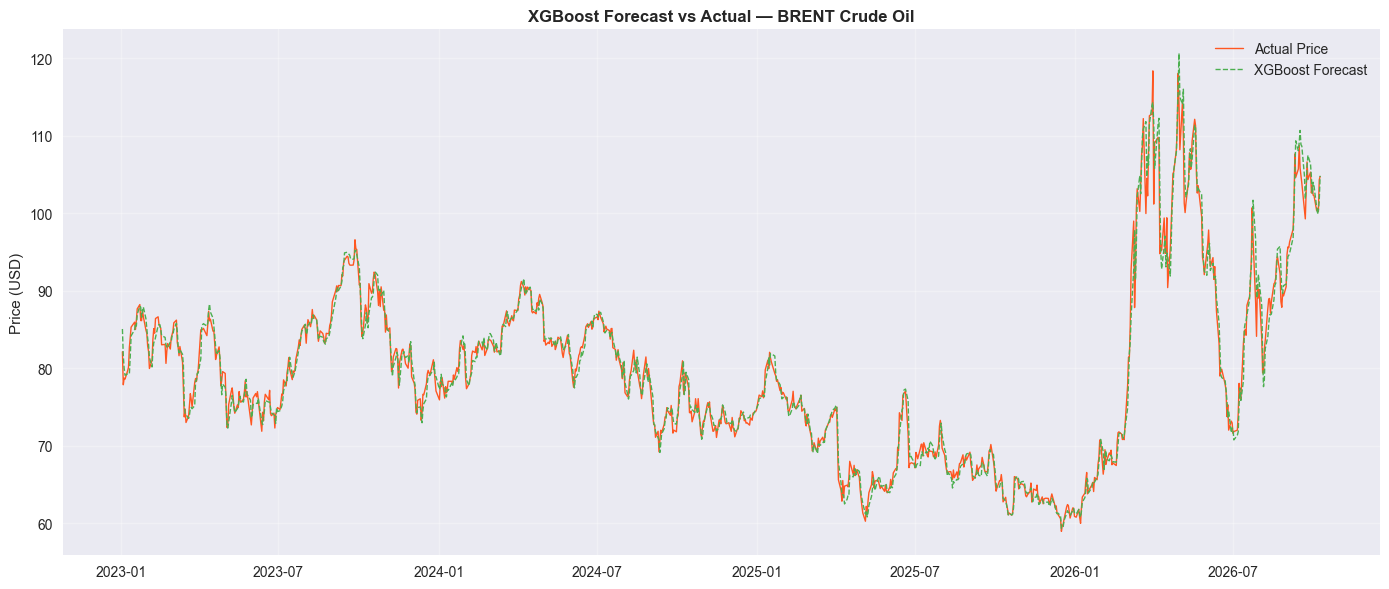

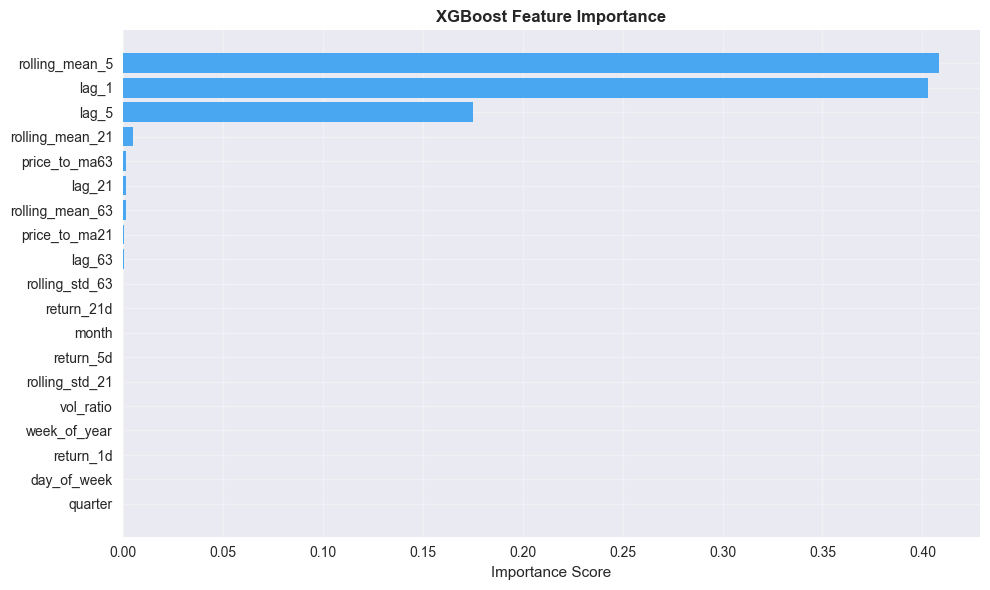

Charts saved!


In [14]:
xgb_predictions = xgb_model.predict(X_test)

# ── Evaluation Metrics ──────────────────────────────────────
actual_xgb    = y_test.values
predicted_xgb = xgb_predictions

mae_x  = mean_absolute_error(actual_xgb, predicted_xgb)
rmse_x = np.sqrt(mean_squared_error(actual_xgb, predicted_xgb))
mape_x = np.mean(np.abs((actual_xgb - predicted_xgb) / 
                          actual_xgb)) * 100

print("="*45)
print("XGBOOST MODEL PERFORMANCE")
print("="*45)
print(f"  MAE  : ${mae_x:.2f}")
print(f"  RMSE : ${rmse_x:.2f}")
print(f"  MAPE : {mape_x:.2f}%")

# ── Plot Actual vs Predicted ─────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(test_xgb.index, actual_xgb,
        color='#FF5722', linewidth=1, label='Actual Price')
ax.plot(test_xgb.index, predicted_xgb,
        color='#4CAF50', linewidth=1,
        linestyle='--', label='XGBoost Forecast')

ax.set_title('XGBoost Forecast vs Actual — BRENT Crude Oil',
             fontweight='bold')
ax.set_ylabel('Price (USD)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/xgboost_forecast.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Feature Importance ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

importance_df = pd.DataFrame({
    'Feature'   : feature_cols,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=True)

ax.barh(importance_df['Feature'], importance_df['Importance'],
        color='#2196F3', alpha=0.8)
ax.set_title('XGBoost Feature Importance', fontweight='bold')
ax.set_xlabel('Importance Score')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/xgboost_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("Charts saved!")

In [15]:
# Naive forecast — just predict yesterday's price
naive_predictions = X_test['lag_1'].values
naive_mape = np.mean(np.abs((actual_xgb - naive_predictions) / 
                              actual_xgb)) * 100
print(f"Naive forecast MAPE (predict yesterday's price): {naive_mape:.2f}%")
print(f"XGBoost MAPE                                   : {mape_x:.2f}%")
print(f"XGBoost improvement over naive                 : {naive_mape - mape_x:.2f}%")

Naive forecast MAPE (predict yesterday's price): 1.69%
XGBoost MAPE                                   : 1.26%
XGBoost improvement over naive                 : 0.43%


In [16]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Model 4 — LSTM (Long Short Term Memory)
Deep learning model that learns from sequences of past prices.
Unlike XGBoost which sees one row at a time,
LSTM sees 60 days of history together and learns temporal patterns.

Key steps:
1. Scale prices to 0-1 range
2. Create 60-day sliding window sequences
3. Build and train LSTM network
4. Inverse transform predictions back to dollar prices

In [17]:
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)

# ── Step 1: Scale data to 0-1 ────────────────────────────────
scaler = MinMaxScaler(feature_range=(0, 1))

# Use only closing price
close_prices = brent[['Close']].values

# Fit scaler on entire dataset
scaled_prices = scaler.fit_transform(close_prices)

print(f"\nOriginal price range: ${close_prices.min():.2f} to ${close_prices.max():.2f}")
print(f"Scaled price range  : {scaled_prices.min():.4f} to {scaled_prices.max():.4f}")

# ── Step 2: Create sequences ─────────────────────────────────
def create_sequences(data, lookback=60):
    """
    Converts flat price array into 3D sequences.
    
    For each day t, creates:
    X = prices from t-60 to t-1  (last 60 days)
    y = price at t               (day to predict)
    """
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, 0])  # last 60 days
        y.append(data[i, 0])              # today's price
    return np.array(X), np.array(y)

LOOKBACK = 60

X_all, y_all = create_sequences(scaled_prices, LOOKBACK)

print(f"\nSequences created:")
print(f"  X shape: {X_all.shape}  (samples, timesteps)")
print(f"  y shape: {y_all.shape}  (samples,)")

TensorFlow version: 2.22.0-rc0

Original price range: $19.33 to $127.98
Scaled price range  : 0.0000 to 1.0000

Sequences created:
  X shape: (4127, 60)  (samples, timesteps)
  y shape: (4127,)  (samples,)


## LSTM — Train/Test Split and Reshape
We split sequences into train and test sets.
LSTM requires 3D input: (samples, timesteps, features)
We reshape from 2D to 3D before feeding to the network.

In [18]:
split_idx = len(brent[brent.index < '2023-01-01']) - LOOKBACK

# Split sequences
X_train_lstm = X_all[:split_idx]
y_train_lstm = y_all[:split_idx]
X_test_lstm  = X_all[split_idx:]
y_test_lstm  = y_all[split_idx:]

print(f"X_train shape: {X_train_lstm.shape}")
print(f"X_test shape : {X_test_lstm.shape}")

# Reshape to 3D — LSTM requires (samples, timesteps, features)
# We have 1 feature (closing price) so last dimension = 1
X_train_lstm = X_train_lstm.reshape(X_train_lstm.shape[0], 
                                     X_train_lstm.shape[1], 1)
X_test_lstm  = X_test_lstm.reshape(X_test_lstm.shape[0], 
                                    X_test_lstm.shape[1], 1)

print(f"\nAfter reshape:")
print(f"X_train shape: {X_train_lstm.shape}  (samples, timesteps, features)")
print(f"X_test shape : {X_test_lstm.shape}  (samples, timesteps, features)")

X_train shape: (3178, 60)
X_test shape : (949, 60)

After reshape:
X_train shape: (3178, 60, 1)  (samples, timesteps, features)
X_test shape : (949, 60, 1)  (samples, timesteps, features)


## LSTM — Network Architecture
We build a 2-layer LSTM network with dropout regularisation.
Dropout prevents overfitting by randomly switching off neurons during training.
EarlyStopping stops training when validation loss stops improving.

In [19]:
model_lstm = Sequential([
    # First LSTM layer
    # 64 units — number of memory cells
    # return_sequences=True — pass output to next LSTM layer
    LSTM(64, return_sequences=True, 
         input_shape=(LOOKBACK, 1)),
    Dropout(0.2),  # randomly switch off 20% of neurons
    
    # Second LSTM layer
    # return_sequences=False — only return final output
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    
    # Output layer — predict 1 value (tomorrow's price)
    Dense(1)
])

# Compile model
model_lstm.compile(
    optimizer='adam',    # adaptive learning rate optimizer
    loss='mse'          # mean squared error loss function
)

# Print model summary
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

## LSTM — Training
We train for up to 50 epochs with early stopping.
Each epoch = one full pass through all training data.
Early stopping stops training when validation loss stops improving
to prevent overfitting.

In [20]:
early_stop = EarlyStopping(
    monitor='val_loss',    # watch validation loss
    patience=10,           # stop after 10 epochs of no improvement
    restore_best_weights=True  # use best weights not last weights
)

print("Training LSTM model...")
print("This will take 3-5 minutes\n")

history = model_lstm.fit(
    X_train_lstm, y_train_lstm,
    epochs=50,              # maximum 50 passes through data
    batch_size=32,          # process 32 samples at a time
    validation_split=0.1,   # use 10% of train data for validation
    callbacks=[early_stop],
    verbose=1               # print progress
)

print("\nTraining complete!")
print(f"Stopped at epoch: {len(history.history['loss'])}")
print(f"Best validation loss: {min(history.history['val_loss']):.6f}")

Training LSTM model...
This will take 3-5 minutes

Epoch 1/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step - loss: 0.0222 - val_loss: 0.0029
Epoch 2/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0055 - val_loss: 0.0030
Epoch 3/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0045 - val_loss: 0.0025
Epoch 4/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0044 - val_loss: 0.0025
Epoch 5/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0037 - val_loss: 0.0025
Epoch 6/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0036 - val_loss: 0.0026
Epoch 7/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0036 - val_loss: 0.0031
Epoch 8/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0032 - val_loss: 0.0022
Epoch 9/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0034 - val_loss: 0.0021
Epoch 10/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0032 - val_loss: 0.0021
Epoch 11/50
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0032 - val_loss: 0.0021
Epoch 12/50


## LSTM — Evaluate and Visualise
We generate predictions, inverse transform from scaled (0-1)
back to actual dollar prices, then calculate metrics.

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
LSTM MODEL PERFORMANCE
  MAE  : $1.95
  RMSE : $2.75
  MAPE : 2.40%


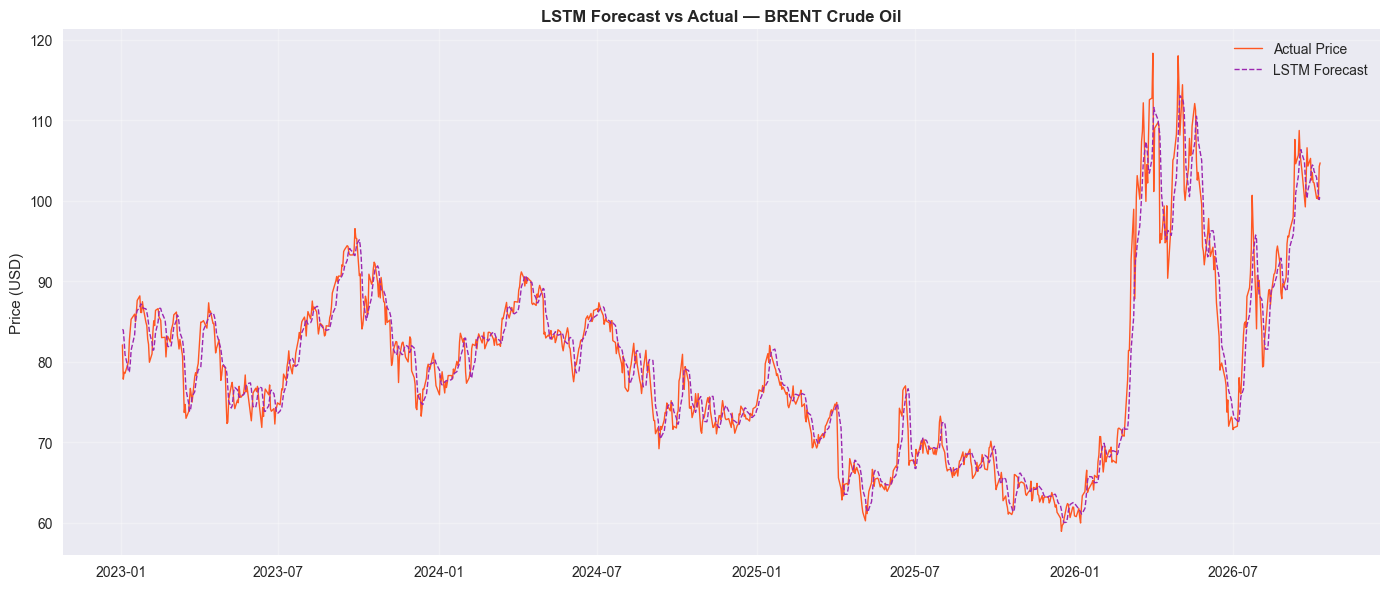

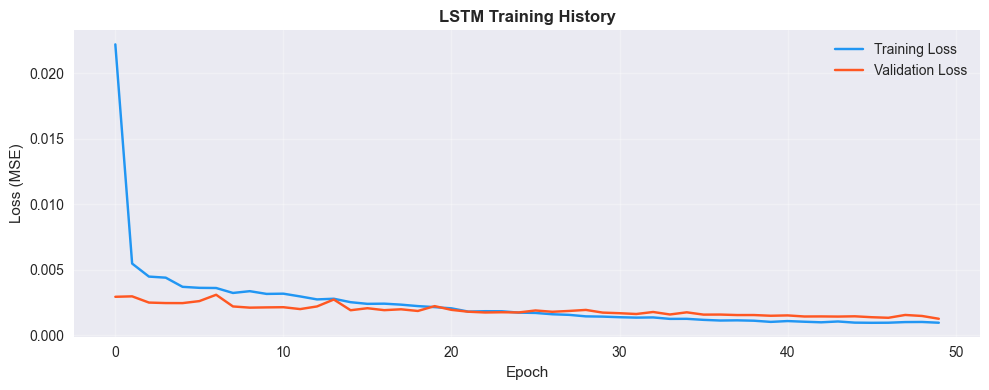

Charts saved!


In [21]:
lstm_predictions_scaled = model_lstm.predict(X_test_lstm)

# Inverse transform — convert scaled predictions back to dollars
lstm_predictions = scaler.inverse_transform(lstm_predictions_scaled)
lstm_actual = scaler.inverse_transform(y_test_lstm.reshape(-1, 1))

# Flatten arrays
lstm_predictions = lstm_predictions.flatten()
lstm_actual_flat = lstm_actual.flatten()

# Get test dates — account for lookback offset
test_dates = brent[brent.index >= '2023-01-01'].index[:len(lstm_actual_flat)]

# ── Evaluation Metrics ──────────────────────────────────────
mae_l  = mean_absolute_error(lstm_actual_flat, lstm_predictions)
rmse_l = np.sqrt(mean_squared_error(lstm_actual_flat, lstm_predictions))
mape_l = np.mean(np.abs((lstm_actual_flat - lstm_predictions) /
                          lstm_actual_flat)) * 100

print("="*45)
print("LSTM MODEL PERFORMANCE")
print("="*45)
print(f"  MAE  : ${mae_l:.2f}")
print(f"  RMSE : ${rmse_l:.2f}")
print(f"  MAPE : {mape_l:.2f}%")

# ── Plot ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(test_dates, lstm_actual_flat,
        color='#FF5722', linewidth=1, label='Actual Price')
ax.plot(test_dates, lstm_predictions,
        color='#9C27B0', linewidth=1,
        linestyle='--', label='LSTM Forecast')

ax.set_title('LSTM Forecast vs Actual — BRENT Crude Oil',
             fontweight='bold')
ax.set_ylabel('Price (USD)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/lstm_forecast.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Training History Plot ────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(history.history['loss'], 
        color='#2196F3', label='Training Loss')
ax.plot(history.history['val_loss'],
        color='#FF5722', label='Validation Loss')

ax.set_title('LSTM Training History', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (MSE)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/lstm_training_history.png', dpi=150, bbox_inches='tight')
plt.show()

print("Charts saved!")

## Final Comparison — All Models Together
We plot all 4 model forecasts against actual prices on one chart.
This is the key visual for portfolio and interviews.

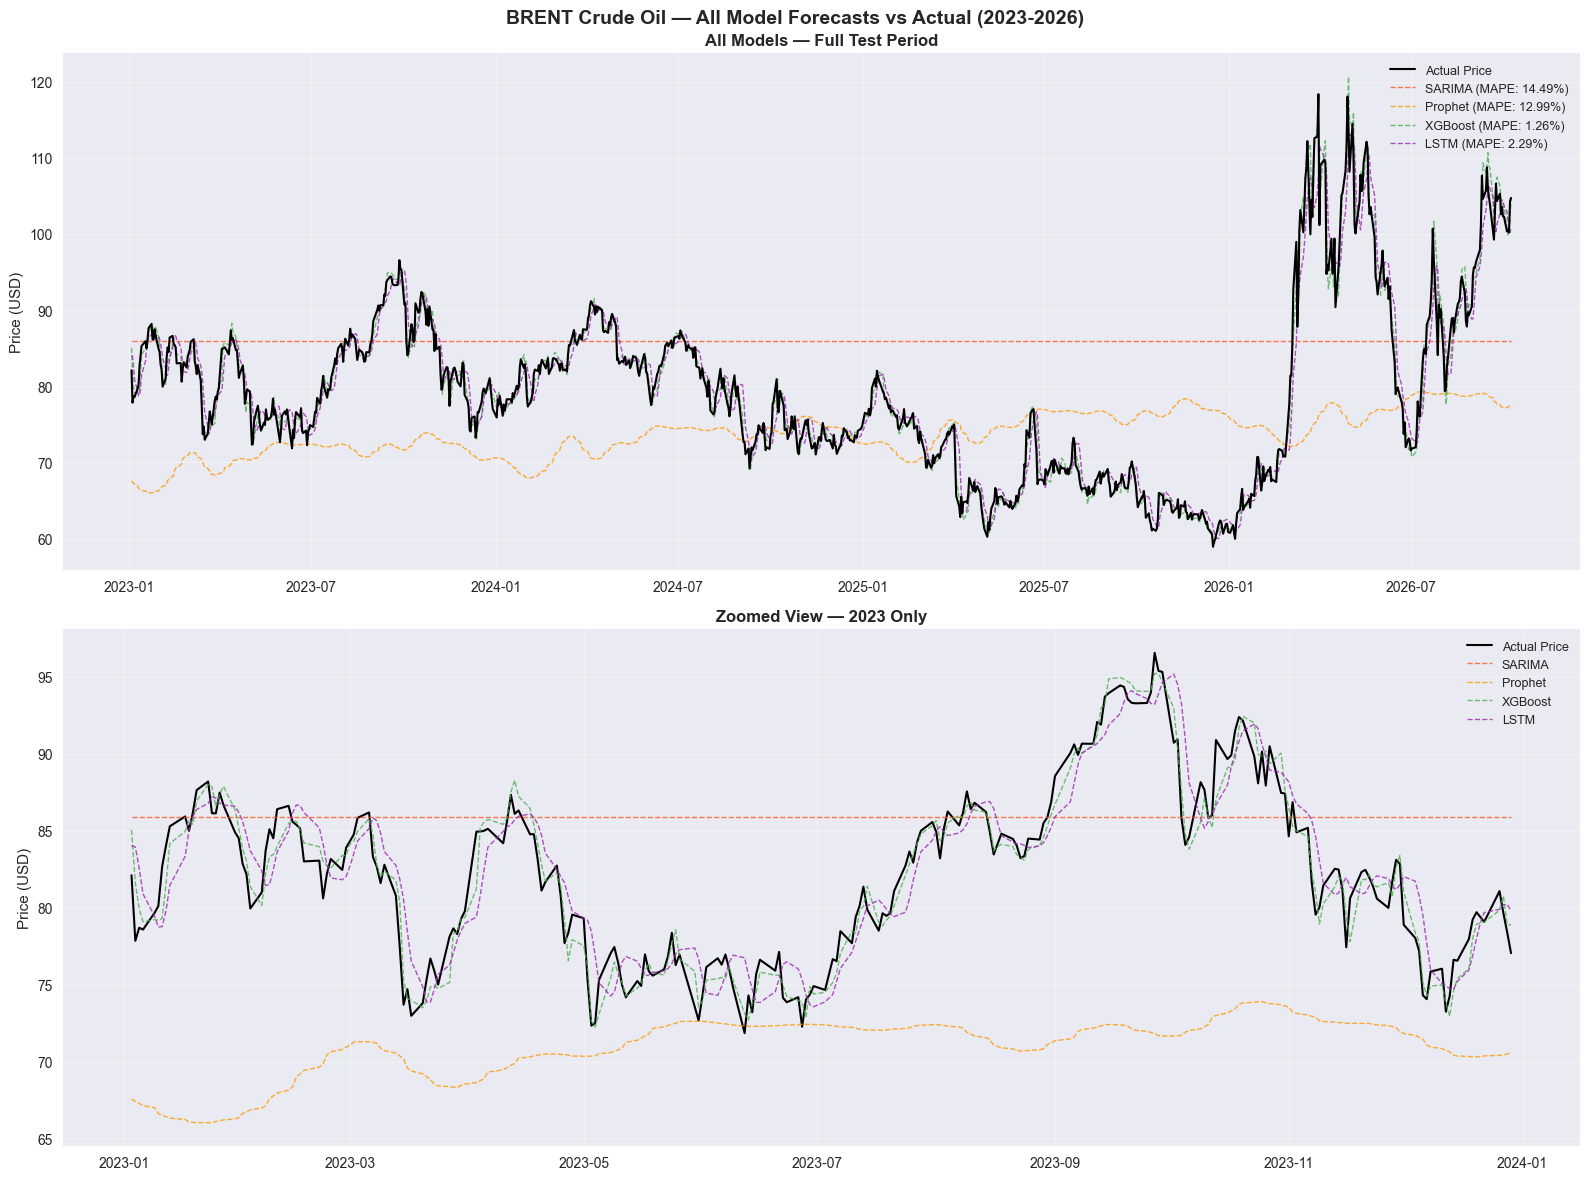

Chart saved!


In [22]:
# ============================================================
# FINAL COMPARISON — ALL MODELS ON ONE CHART
# ============================================================

# Get common date range for all models
# XGBoost and LSTM test sets might differ slightly in length
min_len = min(len(test_xgb), len(lstm_actual_flat), 
              len(actual_prophet))

common_dates = test_xgb.index[:min_len]

fig, axes = plt.subplots(2, 1, figsize=(16, 12))
fig.suptitle('BRENT Crude Oil — All Model Forecasts vs Actual (2023-2026)',
             fontsize=14, fontweight='bold')

# ── Top chart — All models ───────────────────────────────────
ax1 = axes[0]

# Actual prices
ax1.plot(common_dates, 
         test_xgb['Close'].values[:min_len],
         color='black', linewidth=1.5, 
         label='Actual Price', zorder=5)

# SARIMA forecast
ax1.plot(common_dates,
         sarima_forecast.values[:min_len],
         color='#FF5722', linewidth=1,
         linestyle='--', label=f'SARIMA (MAPE: 14.49%)', alpha=0.8)

# Prophet forecast
ax1.plot(common_dates,
         predicted_prophet[:min_len],
         color='#FF9800', linewidth=1,
         linestyle='--', label=f'Prophet (MAPE: 12.99%)', alpha=0.8)

# XGBoost forecast
ax1.plot(common_dates,
         xgb_predictions[:min_len],
         color='#4CAF50', linewidth=1,
         linestyle='--', label=f'XGBoost (MAPE: 1.26%)', alpha=0.8)

# LSTM forecast
ax1.plot(common_dates,
         lstm_predictions[:min_len],
         color='#9C27B0', linewidth=1,
         linestyle='--', label=f'LSTM (MAPE: 2.29%)', alpha=0.8)

ax1.set_title('All Models — Full Test Period', fontweight='bold')
ax1.set_ylabel('Price (USD)')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)

# ── Bottom chart — Zoomed into 2023 ─────────────────────────
ax2 = axes[1]

zoom_mask = common_dates < '2024-01-01'
zoom_dates = common_dates[zoom_mask]

ax2.plot(zoom_dates,
         test_xgb['Close'].values[:zoom_mask.sum()],
         color='black', linewidth=1.5, label='Actual Price')

ax2.plot(zoom_dates,
         sarima_forecast.values[:zoom_mask.sum()],
         color='#FF5722', linewidth=1,
         linestyle='--', label='SARIMA', alpha=0.8)

ax2.plot(zoom_dates,
         predicted_prophet[:zoom_mask.sum()],
         color='#FF9800', linewidth=1,
         linestyle='--', label='Prophet', alpha=0.8)

ax2.plot(zoom_dates,
         xgb_predictions[:zoom_mask.sum()],
         color='#4CAF50', linewidth=1,
         linestyle='--', label='XGBoost', alpha=0.8)

ax2.plot(zoom_dates,
         lstm_predictions[:zoom_mask.sum()],
         color='#9C27B0', linewidth=1,
         linestyle='--', label='LSTM', alpha=0.8)

ax2.set_title('Zoomed View — 2023 Only', fontweight='bold')
ax2.set_ylabel('Price (USD)')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/all_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved!")